<a href="https://colab.research.google.com/github/Habib-103/python/blob/main/second_best_valued_house.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# best-valued house

In [42]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("melb_data.csv")
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000,S,Biggin,3/12/2016,2.5,3067,...,1,1.0,202,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019
1,Abbotsford,25 Bloomburg St,2,h,1035000,S,Biggin,04/02/2016,2.5,3067,...,1,0.0,156,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019
2,Abbotsford,5 Charles St,3,h,1465000,SP,Biggin,04/03/2017,2.5,3067,...,2,0.0,134,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019
3,Abbotsford,40 Federation La,3,h,850000,PI,Biggin,04/03/2017,2.5,3067,...,2,1.0,94,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019
4,Abbotsford,55a Park St,4,h,1600000,VB,Nelson,04/06/2016,2.5,3067,...,1,2.0,120,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019


In [3]:
df.isnull().any()

,0
Suburb,False
Address,False
Rooms,False
Type,False
Price,False
Method,False
SellerG,False
Date,False
Distance,False
Postcode,False


In [4]:
df["CouncilArea"] = df["CouncilArea"].fillna(method='ffill')

<ipython-input-4-ddae5eacb9e8>:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["CouncilArea"] = df["CouncilArea"].fillna(method='ffill')


In [5]:
df.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [6]:
df.dropna(inplace=True)

In [7]:
df.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [8]:
len(df)

6830

In [9]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
1,Abbotsford,25 Bloomburg St,2,h,1035000,S,Biggin,04/02/2016,2.5,3067,...,1,0.0,156,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019
2,Abbotsford,5 Charles St,3,h,1465000,SP,Biggin,04/03/2017,2.5,3067,...,2,0.0,134,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019
4,Abbotsford,55a Park St,4,h,1600000,VB,Nelson,04/06/2016,2.5,3067,...,1,2.0,120,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019
6,Abbotsford,124 Yarra St,3,h,1876000,S,Nelson,07/05/2016,2.5,3067,...,2,0.0,245,210.0,1910.0,Yarra,-37.8024,144.9993,Northern Metropolitan,4019
7,Abbotsford,98 Charles St,2,h,1636000,S,Nelson,8/10/2016,2.5,3067,...,1,2.0,256,107.0,1890.0,Yarra,-37.8060,144.9954,Northern Metropolitan,4019


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6830 entries, 1 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         6830 non-null   object 
 1   Address        6830 non-null   object 
 2   Rooms          6830 non-null   int64  
 3   Type           6830 non-null   object 
 4   Price          6830 non-null   int64  
 5   Method         6830 non-null   object 
 6   SellerG        6830 non-null   object 
 7   Date           6830 non-null   object 
 8   Distance       6830 non-null   float64
 9   Postcode       6830 non-null   int64  
 10  Bedroom2       6830 non-null   int64  
 11  Bathroom       6830 non-null   int64  
 12  Car            6830 non-null   float64
 13  Landsize       6830 non-null   int64  
 14  BuildingArea   6830 non-null   float64
 15  YearBuilt      6830 non-null   float64
 16  CouncilArea    6830 non-null   object 
 17  Lattitude      6830 non-null   float64
 18  Longtitude  

In [11]:
df.Landsize.min()

0

In [12]:
df = df[df['Landsize']>140]

In [13]:
df=df[df['Landsize']<2000]

In [14]:
df["YearBuilt"].min()

1196.0

In [15]:
#price_per

In [16]:
df["Price_per_sqft"] = df["Price"] / df["Landsize"]

In [17]:
df["House_Age"] = 2025 - df["YearBuilt"]

In [18]:
df=df[df['House_Age']<200]

In [19]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount,Price_per_sqft,House_Age
count,5243.000000,5.243000e+03,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000
mean,3.245852,1.189309e+06,11.222830,3104.633797,3.213809,1.683387,1.752432,521.037192,159.976804,1961.199313,-37.805141,144.994542,7204.565325,2846.958273,63.800687
std,0.871799,6.934618e+05,6.064794,97.383820,0.878689,0.741533,0.978855,261.687659,91.317790,36.369602,0.085967,0.115004,4315.062559,2063.081063,36.369602
min,1.000000,1.310000e+05,1.200000,3000.000000,0.000000,1.000000,0.000000,141.000000,0.000000,1854.000000,-38.164920,144.542370,389.000000,139.452333,7.000000
25%,3.000000,7.245000e+05,7.300000,3042.000000,3.000000,1.000000,1.000000,305.000000,110.000000,1935.000000,-37.859285,144.914450,3873.000000,1393.339989,30.000000
50%,3.000000,1.000000e+06,10.500000,3082.000000,3.000000,2.000000,2.000000,536.000000,140.000000,1960.000000,-37.795290,145.004000,6464.000000,2333.955224,65.000000
75%,4.000000,1.455000e+06,13.800000,3147.000000,4.000000,2.000000,2.000000,670.000000,188.500000,1995.000000,-37.748050,145.070100,9264.000000,3683.684127,90.000000
max,8.000000,9.000000e+06,47.400000,3977.000000,9.000000,8.000000,10.000000,1993.000000,3112.000000,2018.000000,-37.408530,145.526350,21650.000000,20476.190476,171.000000


In [20]:
#df=df[df['Price_per_sqft']<2000]

In [21]:
len(df)

5243

In [22]:
6830-2166

4664

In [23]:
#we are trying here to find the best valued house in the context of:
# "Price, Landsize", "Bedroom2", "Bathroom", "Distance", "Price_per_sqft","House_Age"

In [24]:
features = ["Landsize", "Bedroom2", "Bathroom",
             "Distance", "Price_per_sqft","House_Age"]
df_selected = df[features]

In [25]:
df_selected.head()

,Landsize,Bedroom2,Bathroom,Distance,Price_per_sqft,House_Age
1,156,2,1,2.5,6634.615385,125.0
6,245,4,2,2.5,7657.142857,115.0
7,256,2,1,2.5,6390.625000,135.0
9,220,3,1,2.5,4986.363636,125.0
11,214,3,2,2.5,6308.411215,20.0


In [26]:
df_selected.isnull().any()

,0
Landsize,False
Bedroom2,False
Bathroom,False
Distance,False
Price_per_sqft,False
House_Age,False


In [27]:
df_selected.describe()

,Landsize,Bedroom2,Bathroom,Distance,Price_per_sqft,House_Age
count,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000,5243.000000
mean,521.037192,3.213809,1.683387,11.222830,2846.958273,63.800687
std,261.687659,0.878689,0.741533,6.064794,2063.081063,36.369602
min,141.000000,0.000000,1.000000,1.200000,139.452333,7.000000
25%,305.000000,3.000000,1.000000,7.300000,1393.339989,30.000000
50%,536.000000,3.000000,2.000000,10.500000,2333.955224,65.000000
75%,670.000000,4.000000,2.000000,13.800000,3683.684127,90.000000
max,1993.000000,9.000000,8.000000,47.400000,20476.190476,171.000000


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_selected)

In [29]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
wcss = []
for k in range(2, 10):  # Test from 2 to 10 clusters
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)

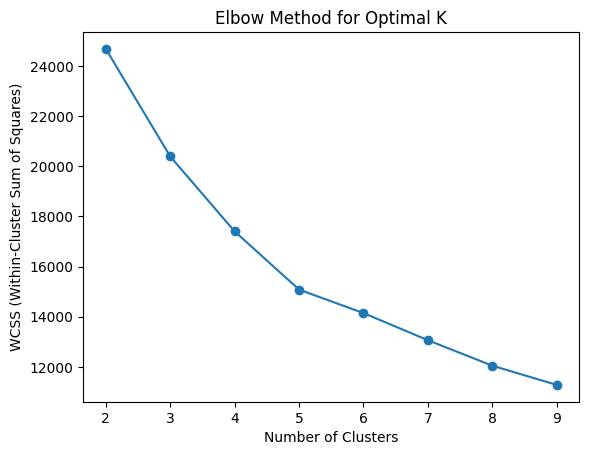

In [30]:
plt.plot(range(2, 10), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.title("Elbow Method for Optimal K")
plt.show()

In [31]:
kmeans = KMeans(n_clusters=5, random_state=42)
df['Cluster'] = kmeans.fit_predict(df_selected)

In [32]:
#we are trying here to find the best valued house in the context of:
# "Landsize", "Bedroom2", "Bathroom", "Distance", "Price_per_sqft","House_Age"

In [33]:
#find the egen values for usage of k-means

In [34]:
cov_matrix = np.cov(df_scaled.T)

In [35]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Display Eigenvalues
print("Eigenvalues:", eigenvalues)

Eigenvalues: [2.15527579 1.56575966 1.05152387 0.60576902 0.26147144 0.36134483]


          Feature  Eigenvalue
0        Landsize    2.155276
1        Bedroom2    1.565760
2        Bathroom    1.051524
3        Distance    0.605769
5       House_Age    0.361345
4  Price_per_sqft    0.261471


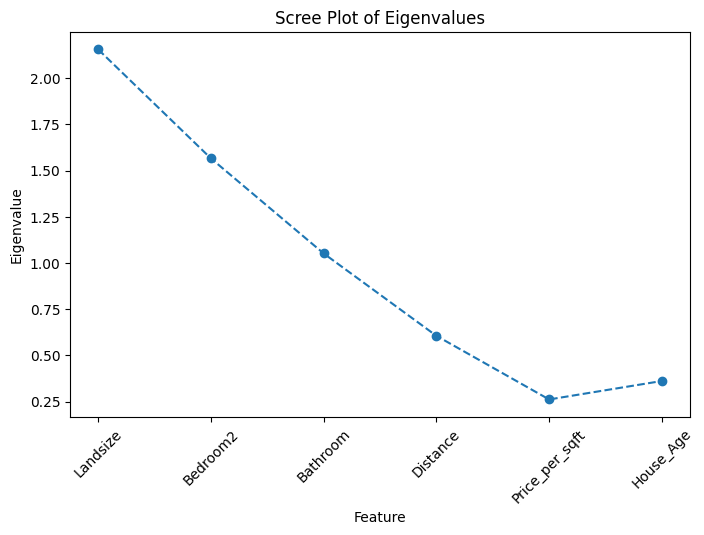

In [36]:
eigen_df = pd.DataFrame({"Feature": features, "Eigenvalue": eigenvalues})

# Display Eigenvalues sorted from highest to lowest
eigen_df = eigen_df.sort_values(by="Eigenvalue", ascending=False)
print(eigen_df)

# Step 6: Plot Scree Plot to visualize importance of each feature
plt.figure(figsize=(8, 5))
plt.plot(features, eigenvalues, marker="o", linestyle="--")
plt.xlabel("Feature")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot of Eigenvalues")
plt.xticks(rotation=45)
plt.show()


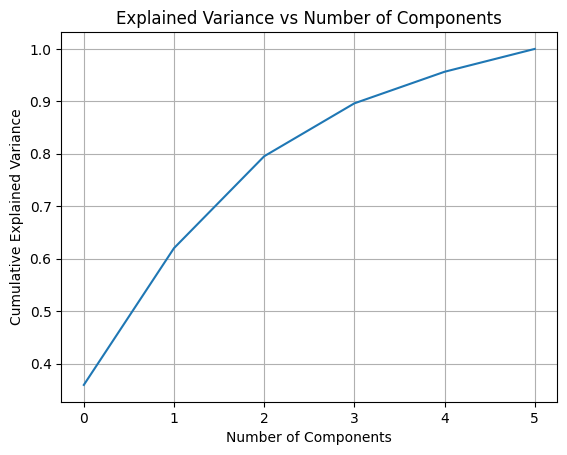

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris

# Apply PCA without reducing components
pca = PCA().fit(df_scaled)

# Plot cumulative explained variance
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs Number of Components')
plt.grid(True)
plt.show()


In [38]:
from sklearn.decomposition import PCA as pca
your_pca = pca(n_components = "mle", svd_solver ="full")
your_pca.fit_transform(df_scaled)
print(your_pca.explained_variance_)

[2.15527579 1.56575966 1.05152387 0.60576902 0.36134483]


In [41]:
pca = PCA(n_components=5)
df_pca = pca.fit_transform(df_scaled)
df['PCA1'] = df_pca[:, 0]
df['PCA2'] = df_pca[:, 1]
df['PCA3'] = df_pca[:, 2]
df['PCA4'] = df_pca[:, 3]
df['PCA5'] = df_pca[:, 4]

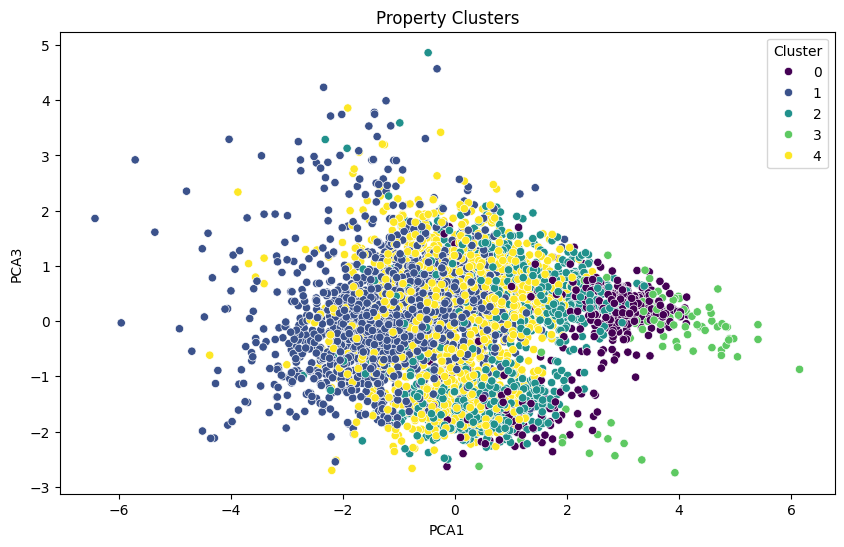

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PCA1', y='PCA3', hue=df['Cluster'], palette='viridis', data=df)
plt.title("Property Clusters")
plt.show()

In [44]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Regionname,Propertycount,Price_per_sqft,House_Age,Cluster,PCA1,PCA2,PCA3,PCA4,PCA5
1,Abbotsford,25 Bloomburg St,2,h,1035000,S,Biggin,04/02/2016,2.5,3067,...,Northern Metropolitan,4019,6634.615385,125.0,0,3.566761,-0.095004,0.182686,0.231920,-0.398159
6,Abbotsford,124 Yarra St,3,h,1876000,S,Nelson,07/05/2016,2.5,3067,...,Northern Metropolitan,4019,7657.142857,115.0,0,2.431579,2.272852,0.363599,0.440313,0.170310
7,Abbotsford,98 Charles St,2,h,1636000,S,Nelson,8/10/2016,2.5,3067,...,Northern Metropolitan,4019,6390.625000,135.0,0,3.446463,-0.158456,0.630002,0.239768,-0.528549
9,Abbotsford,10 Valiant St,2,h,1097000,S,Biggin,8/10/2016,2.5,3067,...,Northern Metropolitan,4019,4986.363636,125.0,2,2.691861,0.196561,0.674003,0.424955,0.519607
11,Abbotsford,40 Nicholson St,3,h,1350000,VB,Nelson,12/11/2016,2.5,3067,...,Northern Metropolitan,4019,6308.411215,20.0,0,1.529202,1.160168,-1.536842,-1.254343,0.189172


In [45]:
cluster_summary = df.groupby('Cluster')['Price'].mean().sort_values()
print("Average Price by Cluster:")
print(round(cluster_summary,0))

Average Price by Cluster:
Cluster
1     798706.0
4    1269667.0
2    1518907.0
0    1714616.0
3    2407143.0
Name: Price, dtype: float64


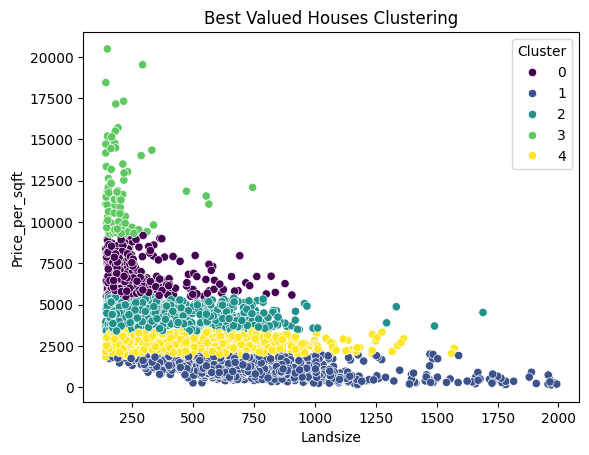

In [46]:
import seaborn as sns

sns.scatterplot(x=df["Landsize"], y=df["Price_per_sqft"], hue=df["Cluster"], palette="viridis")
plt.title("Best Valued Houses Clustering")
plt.show()


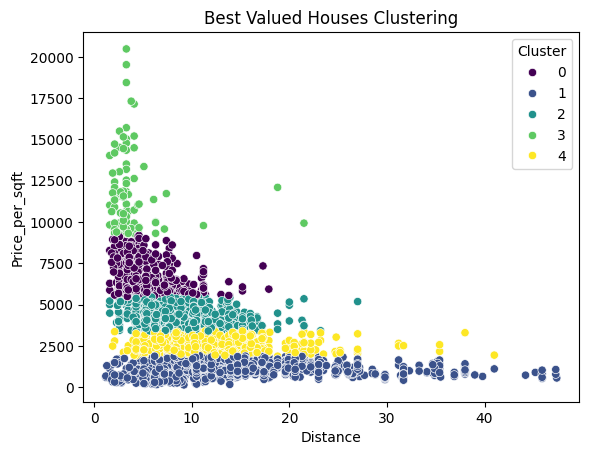

In [47]:
import seaborn as sns

sns.scatterplot(x=df["Distance"], y=df["Price_per_sqft"], hue=df["Cluster"], palette="viridis")
plt.title("Best Valued Houses Clustering")
plt.show()


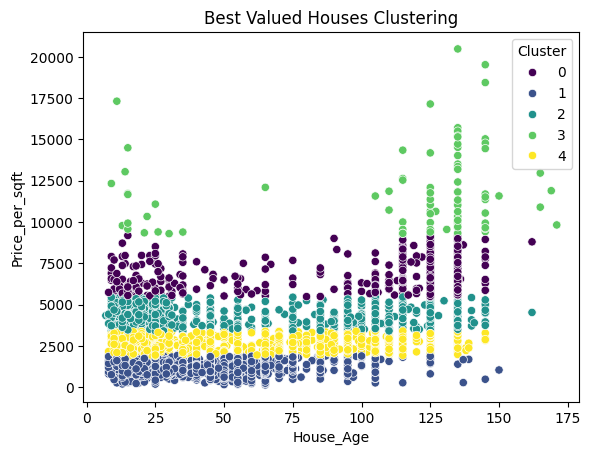

In [48]:
import seaborn as sns

sns.scatterplot(x=df["House_Age"], y=df["Price_per_sqft"], hue=df["Cluster"], palette="viridis")
plt.title("Best Valued Houses Clustering")
plt.show()


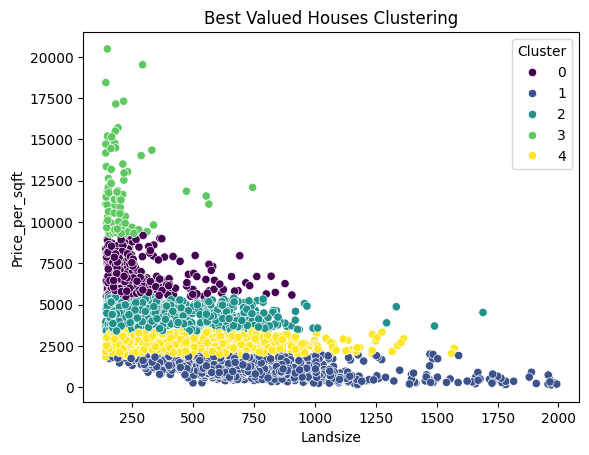

In [49]:
import seaborn as sns

sns.scatterplot(x=df["Landsize"], y=df["Price_per_sqft"], hue=df["Cluster"], palette="viridis")
plt.title("Best Valued Houses Clustering")
plt.show()


In [ ]:
df.to_csv('valued.csv', index=False)

In [ ]:
# so the K means clustering shows:

#based on these features/ factors:
# "Landsize", "Bedroom2", "Bathroom", "Distance", "Price_per_sqft","House_Age"

# - group(0) as the most valued house group, ex: large landsize by for cheap price/sqft  & cheap price/sqft for small land
# - group(1) as the valued house group, ex: medium price for medium landsize. normal or valued houses
# - group(2) is the less valued house group  ex: hgih prices for less land

In [ ]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Price_per_sqft,House_Age,Cluster,PCA1,PCA2
1,Abbotsford,25 Bloomburg St,2,h,1035000,S,Biggin,04/02/2016,2.5,3067,...,Yarra,-37.8079,144.9934,Northern Metropolitan,4019,6634.615385,125.0,1,3804.184206,-98.992924
6,Abbotsford,124 Yarra St,3,h,1876000,S,Nelson,07/05/2016,2.5,3067,...,Yarra,-37.8024,144.9993,Northern Metropolitan,4019,7657.142857,115.0,2,4817.945065,60.604574
7,Abbotsford,98 Charles St,2,h,1636000,S,Nelson,8/10/2016,2.5,3067,...,Yarra,-37.8060,144.9954,Northern Metropolitan,4019,6390.625000,135.0,1,3553.876641,-15.972141
9,Abbotsford,10 Valiant St,2,h,1097000,S,Biggin,8/10/2016,2.5,3067,...,Yarra,-37.8010,144.9989,Northern Metropolitan,4019,4986.363636,125.0,1,2155.509087,-149.789720
11,Abbotsford,40 Nicholson St,3,h,1350000,VB,Nelson,12/11/2016,2.5,3067,...,Yarra,-37.8085,144.9964,Northern Metropolitan,4019,6308.411215,20.0,1,3474.141531,-66.625659


In [ ]:
# Define Melbourne CBD boundary
min_lat, max_lat = -37.839499, 144.985474 # Approximate CBD latitude range
min_lon, max_lon = -37.833263, 144.89827  # Approximate CBD longitude range

# Filter dataset for properties in Melbourne CBD
df_cbd = df[(df["Lattitude"].between(min_lat, max_lat)) &
            (df["Longtitude"].between(min_lon, max_lon))]

# Count occurrences of each cluster in the CBD
cluster_counts = df_cbd["Cluster"].value_counts()

# Display the results
print(cluster_counts)


Cluster
0    702
1    196
2      2
Name: count, dtype: int64


In [ ]:
#-37.839499, 144.985474

In [ ]:
#(-37.833263, 144.89827

In [ ]:
# Define Melbourne CBD boundary
min_lat, max_lat = -37.819704, 144.929512 # Approximate CBD latitude range
min_lon, max_lon = -37.860103, 144.933289 # Approximate CBD longitude range

# Filter dataset for properties in Melbourne CBD
df_cbd = df[(df["Lattitude"].between(min_lat, max_lat)) &
            (df["Longtitude"].between(min_lon, max_lon))]

# Count occurrences of each cluster in the CBD
cluster_counts = df_cbd["Cluster"].value_counts()

# Display the results
print(cluster_counts)


Cluster
0    939
1    335
2      8
Name: count, dtype: int64


In [ ]:
-37.819704, 144.929512
(-37.860103, 144.933289)

(-37.860103, 144.933289)

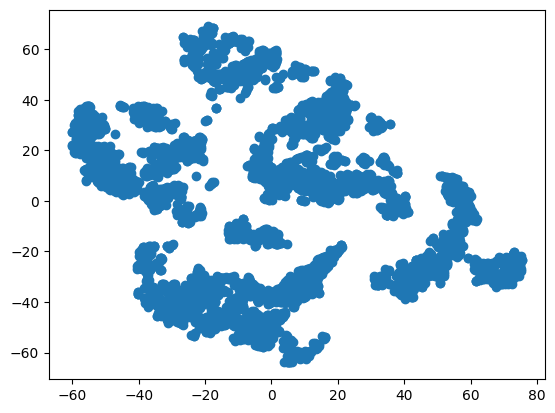

In [60]:
z_tsne = TSNE(n_components=2, perplexity=40).fit_transform(df_scaled)
plt.scatter(z_tsne[:,0],z_tsne[:,1])

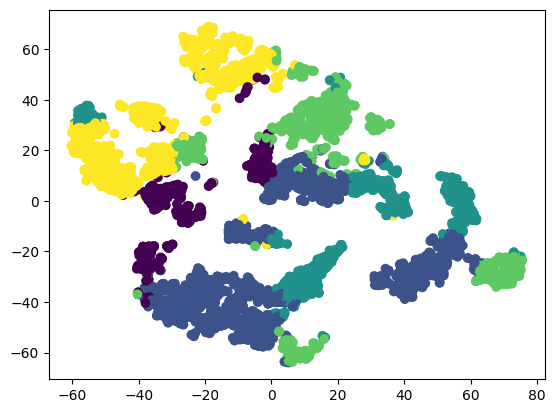

In [61]:
plt.scatter(z_tsne[:,0],z_tsne[:,1], c=kmeans.labels_)

Num clusters 2 Inertia: 24688.75674722861
Num clusters 3 Inertia: 20395.467190539395
Num clusters 4 Inertia: 17404.507428021418
Num clusters 5 Inertia: 15993.925612913774
Num clusters 6 Inertia: 13977.12351009778
Num clusters 7 Inertia: 12906.390693833848
Num clusters 8 Inertia: 11884.347584651658
Num clusters 9 Inertia: 11631.281817533383


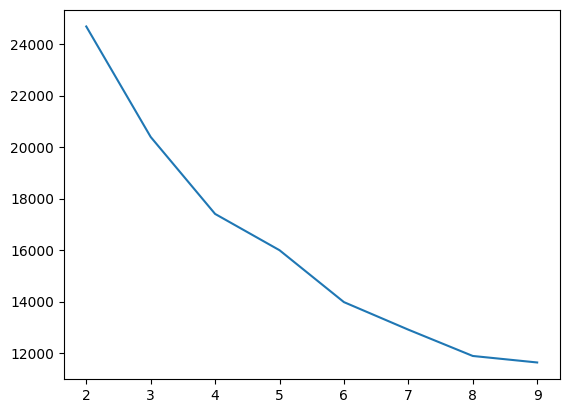

In [62]:
# Would select 3, 4, or 5 clusters
all_kmeans = [i for i in range(8)]
for i in range(8):
    cur_kmeans = KMeans(i+2)
    cur_kmeans.fit(df_scaled[:,0:50])
    print("Num clusters", i+2, "Inertia:", cur_kmeans.inertia_)
    all_kmeans[i] = cur_kmeans
plt.plot([i+2 for i in range(8)], [all_kmeans[i].inertia_ for i in range(8)])

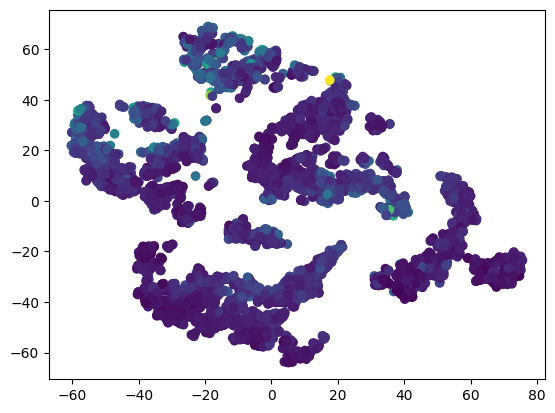

In [63]:
z_tsne = TSNE(n_components=2,perplexity=40).fit_transform(df_scaled)
plt.scatter(z_tsne[:,0],z_tsne[:,1],c=df.Price)

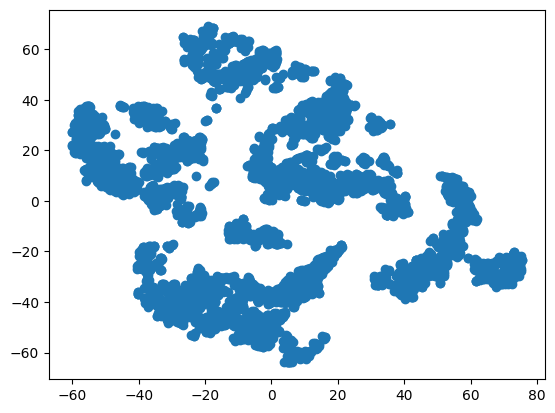

In [64]:
z_tsne = TSNE(n_components=2, perplexity=40).fit_transform(df_scaled)
plt.scatter(z_tsne[:,0],z_tsne[:,1])

In [65]:
#from sklearn.manifold import TSNE, MDS, Isomap

#mds=MDS(n_components=2).fit_transform(df_scaled)
#plt.scatter(mds[:,0],mds[:,1])